In [51]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import loadmat
from scipy.stats import skew, kurtosis

In [58]:
# Load the standing data
magnitude_data_standing = loadmat(r'Zakir_A_P_IQ\N_4m_Standing\Data1\P01A\A.mat')["Data_amplitude"]
phase_data_standing = loadmat(r'Zakir_A_P_IQ\N_4m_Standing\Data1\P01A\P.mat')["Data_phase"]

# Load the sitting data
magnitude_data_sitting = loadmat(r'Zakir_A_P_IQ\N_4m_Sitting\Data1\P01A\A.mat')["Data_amplitude"]
phase_data_sitting = loadmat(r'Zakir_A_P_IQ\N_4m_Sitting\Data1\P01A\P.mat')["Data_phase"]

In [59]:
def plot_activity_statistics(data_standing, data_sitting, statistic_function,ylabel='',name=''):
    values_standing = statistic_function(data_standing, axis=1)
    values_sitting = statistic_function(data_sitting, axis=1)
    range_bins = np.arange(data_standing.shape[0])
    
    plt.plot(range_bins, values_standing, label='Standing', color='blue')
    plt.plot(range_bins, values_sitting, label='Sitting', color='green')
    
    plt.title(f'{ylabel} by Range Bin')
    plt.xlabel('Range Bin')
    plt.ylabel(ylabel)
    plt.legend()
    plt.savefig(name,bbox_inches='tight')
    plt.show()

In [60]:
def equalize_data_shapes(data1, data2):
    min_shape = min(data1.shape[0], data2.shape[0])
    return data1[:min_shape], data2[:min_shape]

magnitude_data_standing, magnitude_data_sitting = equalize_data_shapes(magnitude_data_standing, magnitude_data_sitting)


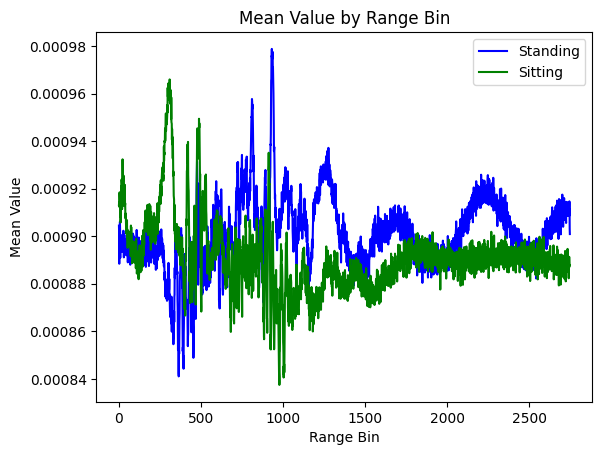

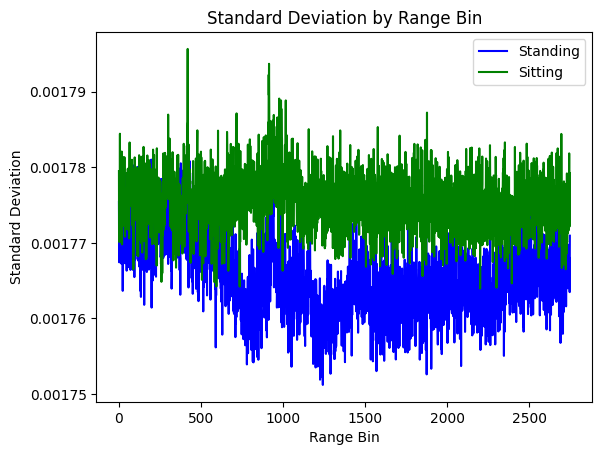

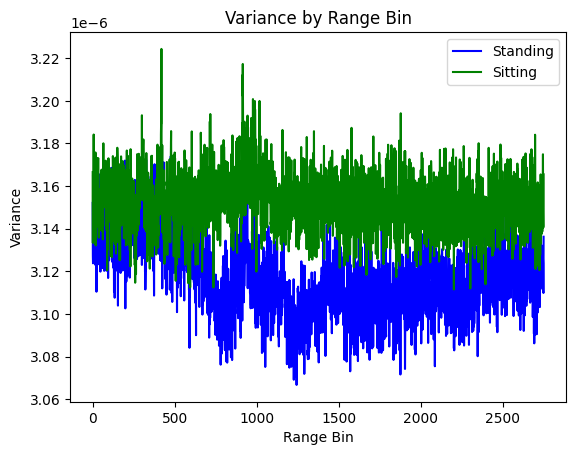

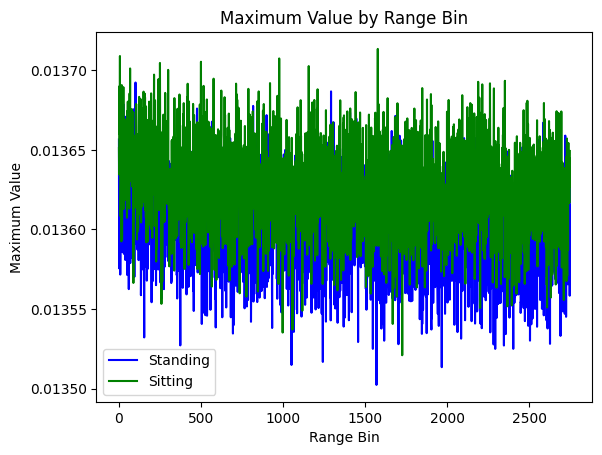

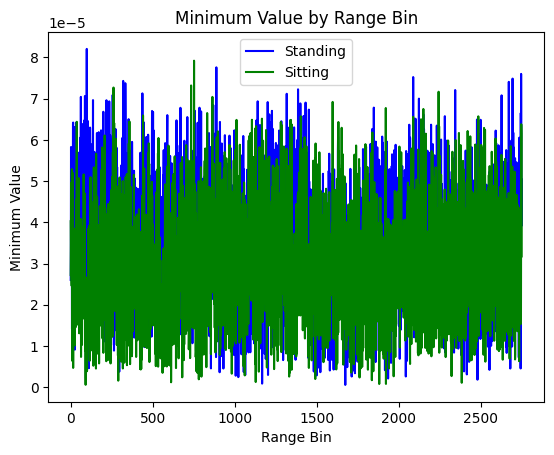

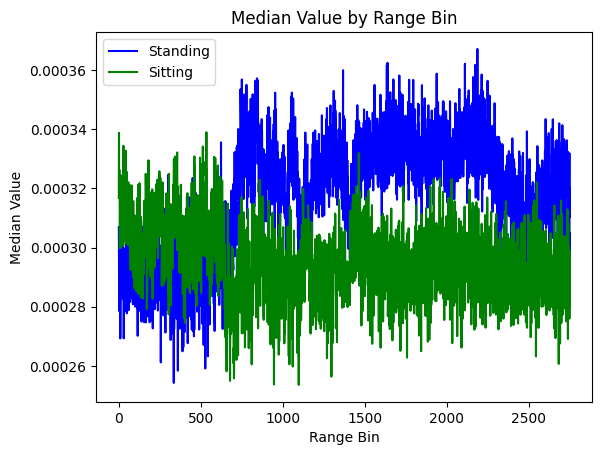

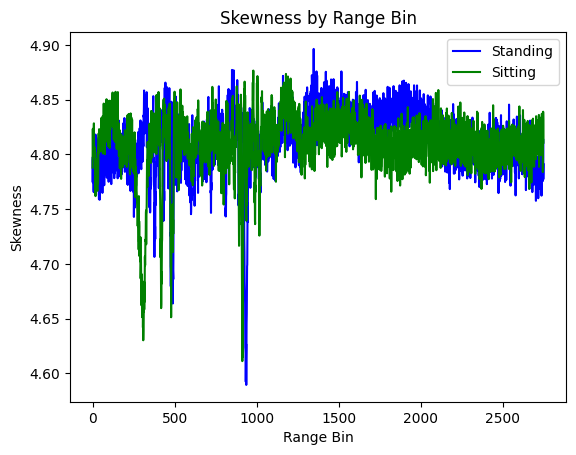

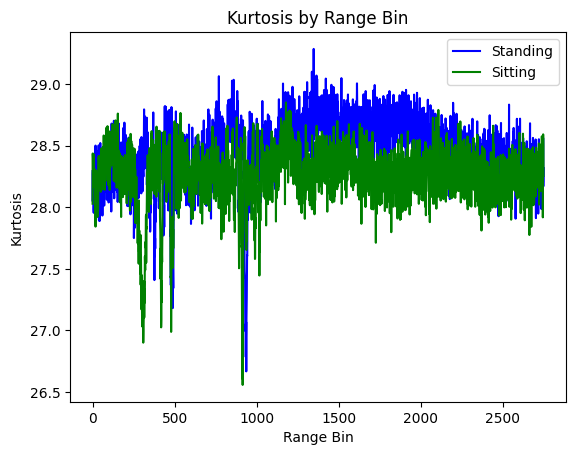

In [61]:
# Mean
plot_activity_statistics(magnitude_data_standing, magnitude_data_sitting, np.mean, 'Mean Value', name = "4m_mean.png")

# Standard Deviation
plot_activity_statistics(magnitude_data_standing, magnitude_data_sitting, np.std, 'Standard Deviation', name = "4m_sd.png")

# Variance
plot_activity_statistics(magnitude_data_standing, magnitude_data_sitting, np.var, 'Variance', name = "4m_var.png")

# Maximum
plot_activity_statistics(magnitude_data_standing, magnitude_data_sitting, np.max, 'Maximum Value', name = "4m_max.png")

# Minimum
plot_activity_statistics(magnitude_data_standing, magnitude_data_sitting, np.min, 'Minimum Value', name = "4m_min.png")

# Median
plot_activity_statistics(magnitude_data_standing, magnitude_data_sitting, np.median, 'Median Value', name = "4m_median.png")

# Skewness
plot_activity_statistics(magnitude_data_standing, magnitude_data_sitting, skew, 'Skewness', name = "4m_skew.png")

# Kurtosis
plot_activity_statistics(magnitude_data_standing, magnitude_data_sitting, kurtosis, 'Kurtosis', name = "4m_kurtosis.png")

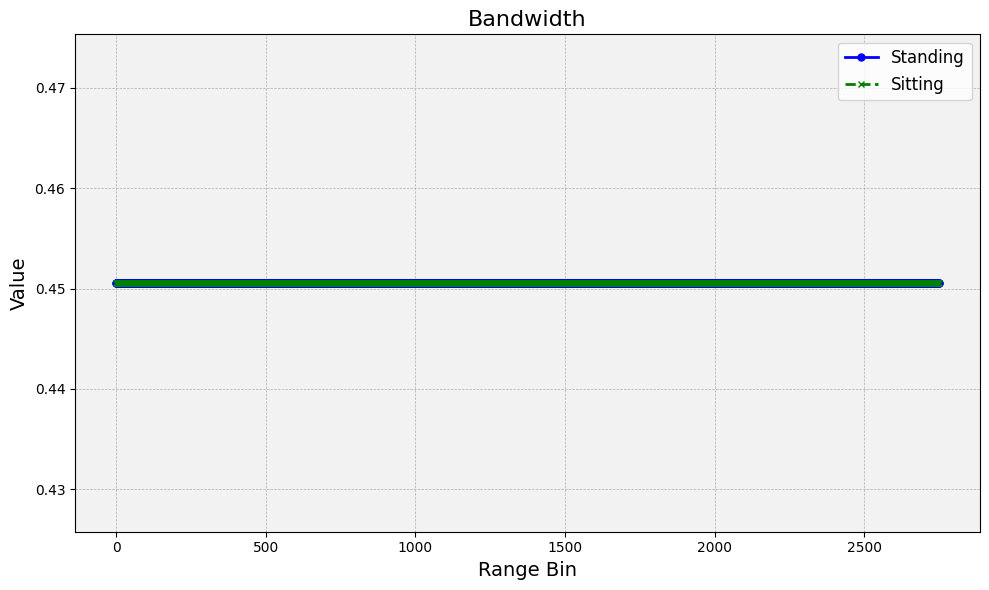

In [62]:
def compute_spectrum(data):
    """Compute the magnitude spectrum of the data."""
    spectrum = np.abs(np.fft.rfft(data, axis=1))
    freqs = np.fft.rfftfreq(data.shape[1])
    return freqs, spectrum

def bandwidth(freqs, spectrum, percentage=0.9):
    """Compute the bandwidth containing a given percentage of the power."""
    total_power = np.sum(spectrum, axis=1)
    cumulative_power = np.cumsum(spectrum, axis=1)
    lower_bound_indices = np.argmax(cumulative_power > total_power[:, None] * ((1 - percentage) / 2), axis=1)
    upper_bound_indices = np.argmax(cumulative_power > total_power[:, None] * (1 - ((1 - percentage) / 2)), axis=1)
    return freqs[upper_bound_indices] - freqs[lower_bound_indices]

def plot_feature_comparison(data_standing, data_sitting, feature_function, title, name):
    values_standing = feature_function(*compute_spectrum(data_standing))
    values_sitting = feature_function(*compute_spectrum(data_sitting))
    
    # Ensure both feature arrays are of the same length
    values_standing, values_sitting = equalize_data_shapes(values_standing, values_sitting)
    
    range_bins = np.arange(len(values_standing))
    
    # Enhanced plotting styles
    plt.figure(figsize=(10,6))
    plt.plot(range_bins, values_standing, label='Standing', color='blue', linestyle='-', linewidth=2, marker='o', markersize=5)
    plt.plot(range_bins, values_sitting, label='Sitting', color='green', linestyle='--', linewidth=2, marker='x', markersize=5)
    
    plt.title(title, fontsize=16)
    plt.xlabel('Range Bin', fontsize=14)
    plt.ylabel('Value', fontsize=14)
    plt.legend(loc='upper right', fontsize=12)
    plt.grid(True, which='both', linestyle='--', linewidth=0.5)
    plt.gca().set_facecolor((0.95, 0.95, 0.95))
    plt.tight_layout()
    plt.savefig(name,bbox_inches='tight')
    plt.show()


# Using the function to plot mean frequency, peak frequency, and bandwidth
plot_feature_comparison(magnitude_data_standing, magnitude_data_sitting, bandwidth, 'Bandwidth', "4m_bandwidth.png")


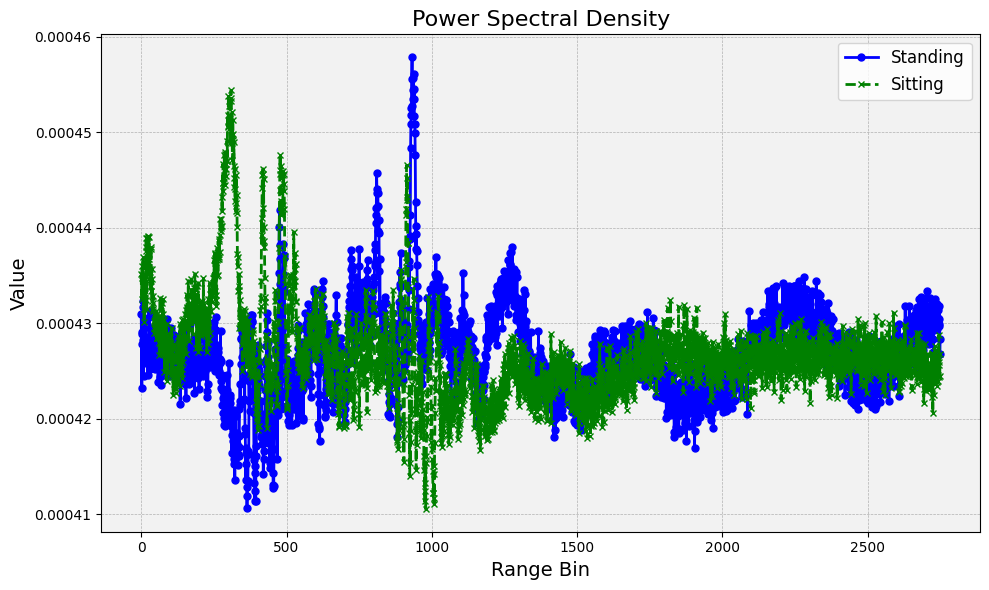

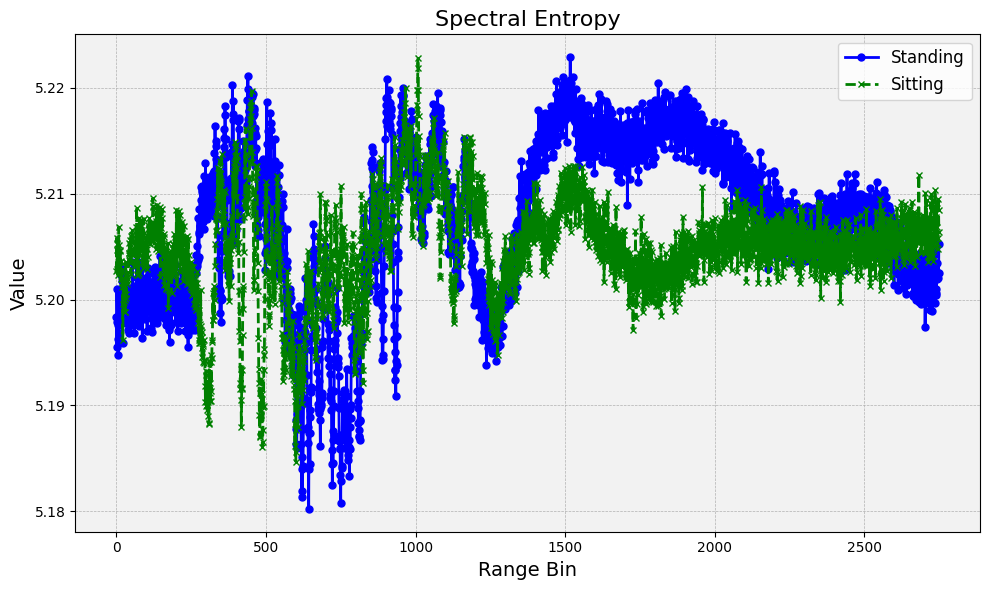

In [63]:
def compute_spectrum(data):
    """Compute the magnitude spectrum of the data."""
    spectrum = np.abs(np.fft.rfft(data, axis=1))
    freqs = np.fft.rfftfreq(data.shape[1])
    return freqs, spectrum

def power_spectral_density(spectrum):
    """Compute the power spectral density."""
    return np.mean(spectrum**2, axis=1)

def spectral_entropy(spectrum):
    """Compute entropy of the spectrum."""
    norm_spectrum = spectrum / np.sum(spectrum, axis=1, keepdims=True)
    entropy = -np.sum(norm_spectrum * np.log2(norm_spectrum + 1e-10), axis=1)  # adding a small value to avoid log(0)
    return entropy

import inspect  # We'll use this to determine the number of arguments a function requires

def plot_feature_comparison(data_standing, data_sitting, feature_function, title, name):
    freqs, spectrum_standing = compute_spectrum(data_standing)
    _, spectrum_sitting = compute_spectrum(data_sitting)
    
    # Determine the number of arguments the feature function requires
    num_args = len(inspect.signature(feature_function).parameters)
    if num_args == 1:
        values_standing = feature_function(spectrum_standing)
        values_sitting = feature_function(spectrum_sitting)
    elif num_args == 2:
        values_standing = feature_function(freqs, spectrum_standing)
        values_sitting = feature_function(freqs, spectrum_sitting)
    else:
        raise ValueError("Function not supported. It should accept either 1 or 2 arguments.")
    
    # Ensure both feature arrays are of the same length
    values_standing, values_sitting = equalize_data_shapes(values_standing, values_sitting)
    
    range_bins = np.arange(len(values_standing))
    
    # Enhanced plotting styles
    plt.figure(figsize=(10,6))
    plt.plot(range_bins, values_standing, label='Standing', color='blue', linestyle='-', linewidth=2, marker='o', markersize=5)
    plt.plot(range_bins, values_sitting, label='Sitting', color='green', linestyle='--', linewidth=2, marker='x', markersize=5)
    
    plt.title(title, fontsize=16)
    plt.xlabel('Range Bin', fontsize=14)
    plt.ylabel('Value', fontsize=14)
    plt.legend(loc='upper right', fontsize=12)
    plt.grid(True, which='both', linestyle='--', linewidth=0.5)
    plt.gca().set_facecolor((0.95, 0.95, 0.95))
    plt.tight_layout()
    plt.savefig(name,bbox_inches='tight')
    plt.show()

# Using the function to plot the additional features
plot_feature_comparison(magnitude_data_standing, magnitude_data_sitting, power_spectral_density, 'Power Spectral Density', "4m_psd")
plot_feature_comparison(magnitude_data_standing, magnitude_data_sitting, spectral_entropy, 'Spectral Entropy', "4m_se")

# 